In [32]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

In [33]:
df = pd.read_csv("C:\\Users\\wasim\\Downloads\\online+shoppers+purchasing+intention+dataset\\online_shoppers_intention.csv")

In [34]:
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [35]:
df.shape

(12330, 18)

In [36]:
df.columns

Index(['Administrative', 'Administrative_Duration', 'Informational',
       'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
       'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month',
       'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType',
       'Weekend', 'Revenue'],
      dtype='str')

In [37]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

In [38]:
df.isnull().sum()

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

In [39]:
df.duplicated().sum()

np.int64(125)

In [40]:
df.describe()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


In [41]:
X = df.drop(['Administrative', 'Cluster', 'Segment'], axis=1, errors='ignore')

In [42]:
X.head()

,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [43]:
print(df.columns.tolist())

['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue']


In [44]:
df['Month'] = df['Month'].astype('category').cat.codes
df['VisitorType'] = df['VisitorType'].astype('category').cat.codes

df['Weekend'] = df['Weekend'].astype(int)

X = df[
    [
        'Administrative',
        'Administrative_Duration',
        'Informational',
        'Informational_Duration',
        'ProductRelated',
        'ProductRelated_Duration',
        'BounceRates',
        'ExitRates',
        'PageValues',
        'SpecialDay',
        'Month',
        'OperatingSystems',
        'Browser',
        'Region',
        'TrafficType',
        'VisitorType',
        'Weekend'
    ]
].copy()

print(X.head())
print(X.shape)

   Administrative  Administrative_Duration  Informational  \
0               0                      0.0              0   
1               0                      0.0              0   
2               0                      0.0              0   
3               0                      0.0              0   
4               0                      0.0              0   

   Informational_Duration  ProductRelated  ProductRelated_Duration  \
0                     0.0               1                 0.000000   
1                     0.0               2                64.000000   
2                     0.0               1                 0.000000   
3                     0.0               2                 2.666667   
4                     0.0              10               627.500000   

   BounceRates  ExitRates  PageValues  SpecialDay  Month  OperatingSystems  \
0         0.20       0.20         0.0         0.0      2                 1   
1         0.00       0.10         0.0         0.0      2

In [45]:
X = df[['Administrative_Duration', 'Informational', 'Informational_Duration']]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("X_scaled created successfully!")
print(X_scaled[:5])

X_scaled created successfully!
[[-0.4571914  -0.3964779  -0.24493051]
 [-0.4571914  -0.3964779  -0.24493051]
 [-0.4571914  -0.3964779  -0.24493051]
 [-0.4571914  -0.3964779  -0.24493051]
 [-0.4571914  -0.3964779  -0.24493051]]


In [46]:
inertia = []
for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

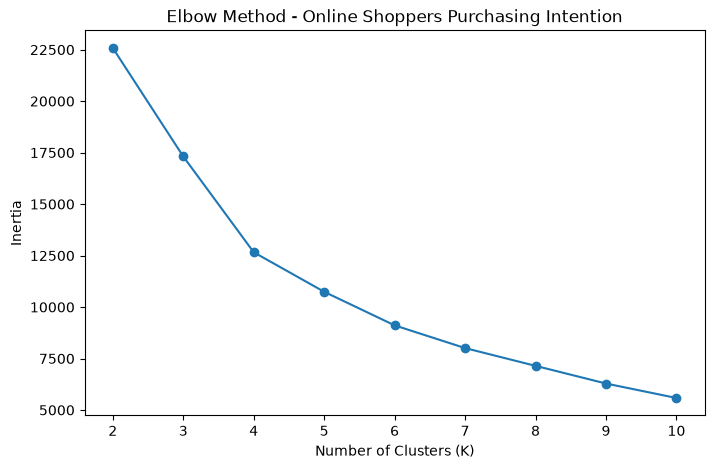

In [50]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    inertia,
    marker='o'
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method - Online Shoppers Purchasing Intention")

plt.show()

In [52]:
kmeans = KMeans(
        n_clusters=4,
        random_state=42,
        n_init=10 
)
cluster = kmeans.fit_predict(X_scaled)

In [53]:
df['Cluster'] = cluster

In [55]:
df['Cluster'].value_counts().sort_index()

Cluster
0    10402
1      163
2     1420
3      345
Name: count, dtype: int64

In [57]:
cluster_summary = df.groupby('Cluster').mean(numeric_only=True)
cluster_summary

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
Cluster,,,,,,,,,,,,,,,,,,
0,1.734666,46.024920,0.086522,2.952460,25.616132,927.411351,0.024869,0.046796,5.481020,0.066353,5.137570,2.128341,2.380888,3.172082,4.141415,1.704384,0.227072,0.138819
1,6.625767,275.345851,4.730061,1010.258902,102.509202,4954.649227,0.007647,0.022847,7.686564,0.031902,5.104294,2.073620,2.171779,2.840491,3.453988,1.914110,0.294479,0.288344
2,4.708451,133.729480,2.954930,148.665573,61.911268,2382.179074,0.007902,0.023406,7.802737,0.037465,5.294366,2.108451,2.217606,3.000000,3.661972,1.788732,0.273239,0.233099
3,7.930435,820.188445,0.991304,53.785102,58.455072,2591.263521,0.007154,0.021318,9.472982,0.025507,5.452174,2.081159,2.301449,3.153623,3.872464,1.756522,0.202899,0.249275


In [58]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

In [59]:
print(X_pca.shape)

(12330, 2)


In [60]:
clusters = df['Cluster'].values
print(len(clusters))

12330


In [62]:
pca_df = pd.DataFrame(
    X_pca,
    columns=['PC1', 'PC2']
)
pca_df['Cluster'] = clusters
pca_df.head()

,PC1,PC2,Cluster
0,-0.60777,-0.225234,0
1,-0.60777,-0.225234,0
2,-0.60777,-0.225234,0
3,-0.60777,-0.225234,0
4,-0.60777,-0.225234,0


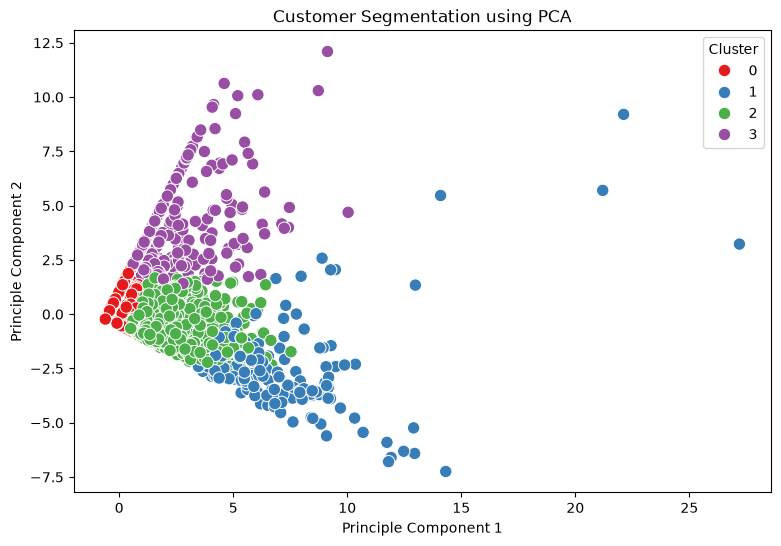

In [64]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='Cluster',
    palette='Set1',
    s=80
)
plt.title("Customer Segmentation using PCA")
plt.xlabel("Principle Component 1")
plt.ylabel("Principle Component 2")
plt.show()

In [65]:
print(
    "PC1 Variance:",
    pca.explained_variance_ratio_[0]
)
print(
    "PC2 Variance:",
    pca.explained_variance_ratio_[1]
)
print(
    "Total Variance:",
    pca.explained_variance_ratio_.sum()
)

PC1 Variance: 0.600553927752058
PC2 Variance: 0.2738106227732079
Total Variance: 0.8743645505252658


In [67]:
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue,Cluster
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,2,1,1,1,1,2,0,False,0
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,2,2,2,1,2,2,0,False,0
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,2,4,1,9,3,2,0,False,0
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,2,3,2,2,4,2,0,False,0
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,2,3,3,1,4,2,1,False,0


In [68]:
profile = df.groupby('Cluster').agg({
    'Administrative': 'mean',
    'Administrative_Duration': 'mean',
    'Informational':	'mean',
    'ProductRelated': 'mean',
    'ProductRelated_Duration': 'mean',
    'BounceRates': 'mean',
    'ExitRates': 'mean',
    'PageValues': 'mean',
    'SpecialDay': 'mean',
    'Month': 'mean',
    'OperatingSystems': 'mean',
    'Browser': 'mean',
    'Region': 'mean',
    'TrafficType': 'mean',
    'VisitorType': 'mean',
    'Weekend': 'mean',
    'Revenue': 'mean',
    'Cluster': 'mean',
}).round(2)
profile

,Administrative,Administrative_Duration,Informational,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue,Cluster
Cluster,,,,,,,,,,,,,,,,,,
0,1.73,46.02,0.09,25.62,927.41,0.02,0.05,5.48,0.07,5.14,2.13,2.38,3.17,4.14,1.70,0.23,0.14,0.0
1,6.63,275.35,4.73,102.51,4954.65,0.01,0.02,7.69,0.03,5.10,2.07,2.17,2.84,3.45,1.91,0.29,0.29,1.0
2,4.71,133.73,2.95,61.91,2382.18,0.01,0.02,7.80,0.04,5.29,2.11,2.22,3.00,3.66,1.79,0.27,0.23,2.0
3,7.93,820.19,0.99,58.46,2591.26,0.01,0.02,9.47,0.03,5.45,2.08,2.30,3.15,3.87,1.76,0.20,0.25,3.0


In [71]:
cluster_names = {
    0: 'Young High-Income',
    1: 'Price-Sensitive',
    2: 'VIP Premium',
    3: 'Regular Customer'
}

df['Segment'] = df['Cluster'].map(cluster_names)

print(df[['Cluster', 'Segment']].head())

   Cluster            Segment
0        0  Young High-Income
1        0  Young High-Income
2        0  Young High-Income
3        0  Young High-Income
4        0  Young High-Income


In [73]:
df[['Administrative', 'Cluster', 'Segment']].head(20)

,Administrative,Cluster,Segment
0,0,0,Young High-Income
1,0,0,Young High-Income
2,0,0,Young High-Income
3,0,0,Young High-Income
4,0,0,Young High-Income
5,0,0,Young High-Income
6,0,0,Young High-Income
7,1,0,Young High-Income
8,0,0,Young High-Income
9,0,0,Young High-Income


In [74]:
df['Segment'].value_counts()

Segment
Young High-Income    10402
VIP Premium           1420
Regular Customer       345
Price-Sensitive        163
Name: count, dtype: int64

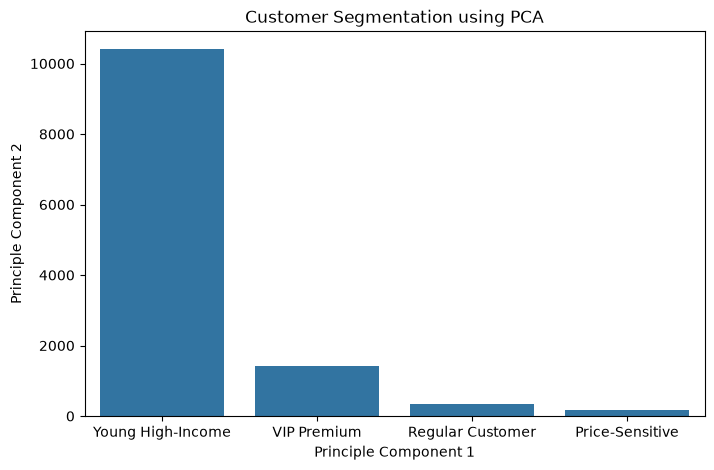

In [75]:
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x='Segment'
)
plt.title("Customer Segmentation using PCA")
plt.xlabel("Principle Component 1")
plt.ylabel("Principle Component 2")
plt.show()

In [76]:
df.to_csv(
    "customer_segmentation_result.csv",
    index=False
)

In [77]:
import joblib
joblib.dump(
    kmeans,
    "customer_segmentation_kmeans.pkl",
)

['customer_segmentation_kmeans.pkl']